# XGBoost Classifier

## Project: Credit Risk Scoring System Using Multivariate Statistical Analysis and Machine Learning

### Notebook Objectives

Extreme Gradient Boosting (XGBoost) is a high-performance ensemble learning algorithm based on gradient boosting decision trees. It has become one of the most widely adopted algorithms for structured data classification problems due to its accuracy, computational efficiency, and robustness.

In this notebook, an XGBoost classifier is trained using the PCA-transformed applicant dataset to predict loan default.

The objectives are to:

- Train an XGBoost classifier.
- Predict applicant default probability.
- Evaluate model performance.
- Analyze feature importance.
- Compare the model with previously developed classifiers.

# Import Required Libraries

The following libraries are used for model development, evaluation, and visualization.

In [4]:
# ============================================================
# Import Libraries
# ============================================================

import warnings
from pathlib import Path

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

plt.style.use("ggplot")
sns.set_theme(style="whitegrid")

# Load Training and Testing Data

The PCA-transformed training and testing datasets prepared during feature engineering are loaded for model development.

In [5]:
# ============================================================
# Load Dataset
# ============================================================

DATA_DIR = Path("../data/processed")

X_train = pd.read_csv(DATA_DIR / "X_train.csv")
X_test = pd.read_csv(DATA_DIR / "X_test.csv")

y_train = pd.read_csv(DATA_DIR / "y_train.csv").squeeze()
y_test = pd.read_csv(DATA_DIR / "y_test.csv").squeeze()

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

Training: (246008, 119)
Testing : (61503, 119)


# Train XGBoost Model

An XGBoost classifier is trained using the training dataset.

The selected hyperparameters provide a balance between predictive performance and overfitting control.

In [16]:
# ============================================================
# Train XGBoost
# ============================================================

scale_pos_weight = (
    y_train.value_counts()[0] /
    y_train.value_counts()[1]
)

xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    X_train,
    y_train
)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


# Generate Predictions

The trained XGBoost classifier predicts both applicant class labels and the probability of default.

In [17]:
# ============================================================
# Predictions
# ============================================================

y_pred = xgb_model.predict(X_test)

y_prob = xgb_model.predict_proba(X_test)[:,1]

# Model Evaluation

The XGBoost classifier is evaluated using:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

In [18]:
accuracy = accuracy_score(y_test,y_pred)

precision = precision_score(y_test,y_pred)

recall = recall_score(y_test,y_pred)

f1 = f1_score(y_test,y_pred)

auc = roc_auc_score(y_test,y_prob)

metrics = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC AUC"
    ],

    "Value":[
        accuracy,
        precision,
        recall,
        f1,
        auc
    ]
})

metrics

,Metric,Value
0,Accuracy,0.745264
1,Precision,0.181184
2,Recall,0.612487
3,F1 Score,0.279645
4,ROC AUC,0.752078


# Confusion Matrix

The confusion matrix summarizes the classification performance of the XGBoost classifier.

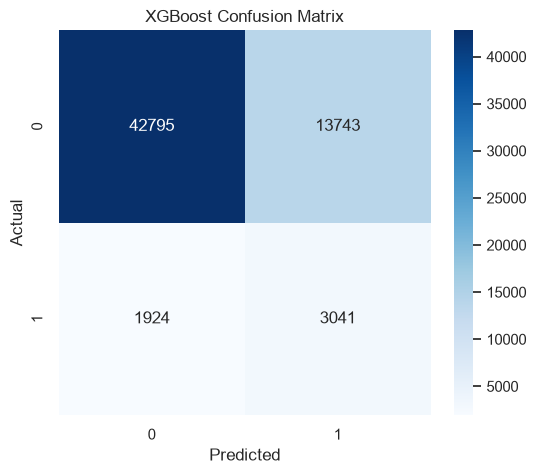

In [19]:
cm = confusion_matrix(y_test,y_pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title("XGBoost Confusion Matrix")

plt.show()

# Classification Report

The classification report summarizes precision, recall, F1-score, and support for each class.

In [20]:
print(classification_report(
    y_test,
    y_pred
))

              precision    recall  f1-score   support

           0       0.96      0.76      0.85     56538
           1       0.18      0.61      0.28      4965

    accuracy                           0.75     61503
   macro avg       0.57      0.68      0.56     61503
weighted avg       0.89      0.75      0.80     61503



# ROC Curve

The ROC Curve illustrates the classifier's ability to distinguish between default and non-default applicants across varying classification thresholds.

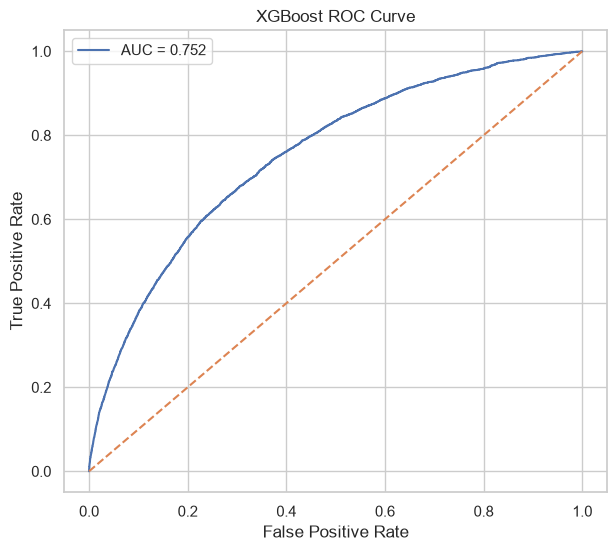

In [21]:
fpr,tpr,_ = roc_curve(
    y_test,
    y_prob
)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    label=f"AUC = {auc:.3f}"
)

plt.plot([0,1],[0,1],"--")

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("XGBoost ROC Curve")

plt.legend()

plt.grid(True)

plt.show()

# Feature Importance

XGBoost estimates feature importance based on the contribution of each feature to improving the model's predictive performance.

Since PCA components are used as predictors, the importance values indicate the relative contribution of each principal component.

In [22]:
feature_importance = (

    pd.DataFrame({

        "Feature":X_train.columns,

        "Importance":xgb_model.feature_importances_

    })

    .sort_values(
        "Importance",
        ascending=False
    )

)

feature_importance.head(15)

,Feature,Importance
8,PC9,0.045603
17,PC18,0.030325
7,PC8,0.029381
2,PC3,0.022446
19,PC20,0.021408
1,PC2,0.019959
28,PC29,0.015884
30,PC31,0.015550
25,PC26,0.015273
6,PC7,0.014390


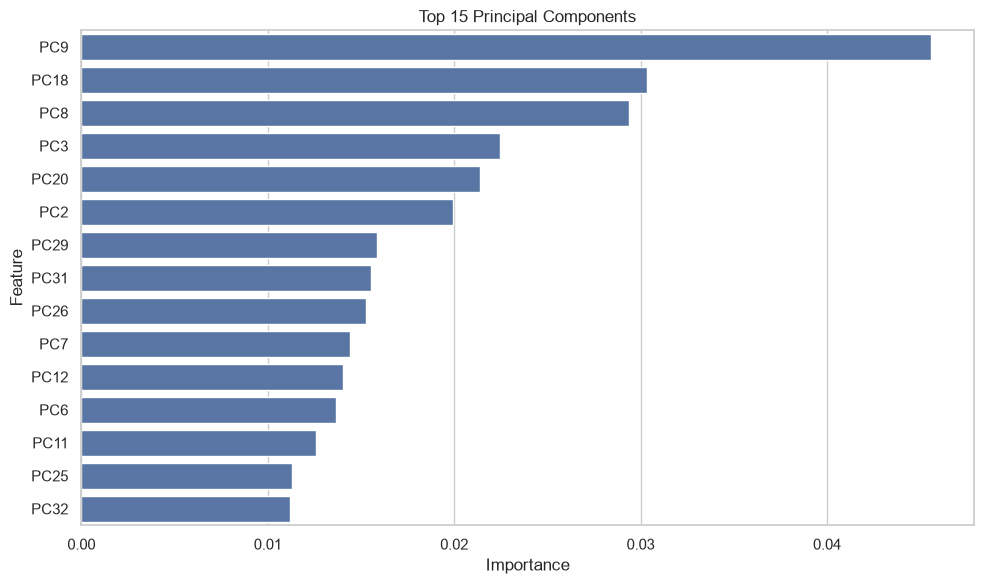

In [23]:
plt.figure(figsize=(10,6))

sns.barplot(

    data=feature_importance.head(15),

    x="Importance",

    y="Feature"

)

plt.title("Top 15 Principal Components")

plt.tight_layout()

plt.show()

# Model Configuration

The XGBoost classifier was trained using:

- Number of Trees = 300
- Learning Rate = 0.05
- Maximum Tree Depth = 6
- Subsample = 0.80
- Column Sample by Tree = 0.80

These parameters provide a balance between model complexity, learning speed, and generalization performance.

# Save Trained Model

The trained Logistic Regression model is saved for future prediction, evaluation, and deployment.

In [25]:
# ============================================================
# Save XGBoost Model
# ============================================================

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    xgb_model,
    MODEL_DIR / "xgboost_model.pkl"
)

print("XGBoost model saved successfully.")

XGBoost model saved successfully.


# Save Model Performance

The evaluation metrics of the XGBoost classifier are appended to the common model results file for comparison with all previously developed machine learning models.

In [24]:
# ============================================================
# Save Model Performance
# ============================================================

from pathlib import Path

OUTPUT_DIR = Path("../results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

results_file = OUTPUT_DIR / "model_results.csv"

current_result = pd.DataFrame({

    "Model": ["XGBoost"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "ROC AUC": [auc],

    "False Positives": [cm[0,1]],

    "False Negatives": [cm[1,0]],

    "True Positives": [cm[1,1]],

    "True Negatives": [cm[0,0]]

})

if results_file.exists():

    existing_results = pd.read_csv(results_file)

    existing_results = pd.concat(
        [existing_results, current_result],
        ignore_index=True
    )

    existing_results.to_csv(
        results_file,
        index=False
    )

else:

    current_result.to_csv(
        results_file,
        index=False
    )

print("Model results saved successfully.")

current_result

Model results saved successfully.


,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,False Positives,False Negatives,True Positives,True Negatives
0,XGBoost,0.745264,0.181184,0.612487,0.279645,0.752078,13743,1924,3041,42795


# Conclusion

The XGBoost classifier was successfully trained and evaluated using the PCA-transformed applicant dataset.

## Key Outcomes

- A gradient boosting ensemble model was developed for credit risk prediction.
- Performance was assessed using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
- Feature importance analysis identified the principal components that contributed most to the model's predictions.
- The confusion matrix and ROC curve demonstrated the classifier's discriminative ability.
- Performance metrics were saved for comparison with the remaining machine learning models.

**Notebook Status:** ✅ Completed

**Next Notebook:** **Notebook 12 – LightGBM Classifier**